<a href="https://colab.research.google.com/github/LinaMariaCastro/curso-ia-para-economia/blob/main/clases/4_Aprendizaje_no_supervisado/1_Taller_Clustering_Pymes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** [Lina María Castro](https://www.linkedin.com/in/lina-maria-castro)
- 📧 **Email:** [lmcastroco@gmail.com](mailto:lmcastroco@gmail.com)
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# 🏭 **Taller: Segmentación del Tejido Empresarial Colombiano**
---

**IMPORTANTE**: Guarda una copia de este notebook en tu Google Drive o computador.

**Taller en parejas.**

**Nombres estudiantes:**

-Julian Lizarazo
-Nicolas Orduña

**Forma de entrega:**

- Nombrar el archivo de la siguiente forma:“Taller_Clustering_apellidos.ipynb”.
- Suba el Jupyter Notebook a su cuenta en Github y envíe el link en el siguiente Forms: https://forms.cloud.microsoft/r/Nr3n9tg3fj.

**IMPORTANTE:** No se recibirán talleres en Google Colab, el notebook debe estar subido en Github.

**Plazo de entrega:**

16 de octubre de 2026, máximo a las 11:59 p.m. Tenga en cuenta que luego de esa hora el formulario en forms se cierra. El Jupupyter Notebook también debe quedar subido en Github antes de esa hora.

## 📄 Caso de Estudio: Consultoría para Bancóldex y el MinCIT

**Contexto:** Bancóldex y el Ministerio de Comercio, Industria y Turismo destinan cada año un presupuesto limitado a apoyar a las micro, pequeñas y medianas empresas del país. Hasta ahora han usado un **único paquete de instrumentos para todas**: la misma línea de crédito, el mismo programa de capacitación y la misma convocatoria de internacionalización, sin importar si la empresa es una tienda de barrio con tres empleados o una manufactura mediana con ciento cincuenta.

La evaluación de impacto del año pasado fue demoledora: el programa no movió la aguja en casi ningún indicador. La hipótesis del equipo técnico es que el problema no es el monto, sino la **focalización**: empresas con necesidades muy distintas están recibiendo exactamente lo mismo.

**Tu misión:** tu equipo de consultoría recibió una base con **250 empresas** y sus indicadores financieros, productivos y de internacionalización. Deben aplicar técnicas de **clustering** para descubrir si existen segmentos con perfiles diferenciados, caracterizar cada uno y proponer instrumentos de política específicos para ellos.

> **Ojo:** nadie les va a decir cuántos grupos hay ni cómo se llaman. Eso es precisamente lo que tienen que descubrir y **justificar** con los datos.

## 💾 Diccionario de datos — `pymes_colombia.csv`

| Columna | Tipo | Descripción |
|---|---|---|
| `empresa` | Texto | Código anonimizado de la empresa (`PYME_001`, …). **No entra al clustering.** |
| `ventas_anuales` | Numérica | Ventas del último año fiscal, en millones de pesos. |
| `empleados` | Numérica | Número de empleados con contrato vigente. |
| `productividad` | Numérica | Ventas por empleado, en millones de pesos. |
| `margen_operacional` | Numérica | Utilidad operacional sobre ventas (%). Puede ser negativo. |
| `endeudamiento` | Numérica | Pasivo total sobre activo total (%). |
| `exportaciones_pct` | Numérica | Porcentaje de las ventas destinado a mercados externos. |
| `inversion_tic` | Numérica | Inversión en tecnología como porcentaje de las ventas. |
| `antiguedad` | Numérica | Años desde la constitución legal de la empresa. |
| `crecimiento_ventas` | Numérica | Variación porcentual de las ventas frente al año anterior. |
| `sector` | Categórica | Agroindustria, Comercio, Manufactura, Servicios o TIC. |
| `region` | Categórica | Andina, Caribe, Eje Cafetero o Pacífica. |

## 📋 Instrucciones generales

- Completen el código en las celdas marcadas con `### TU CÓDIGO AQUÍ ###`. Pueden añadir todas las celdas que necesiten.
- **No modifiquen** la celda de verificación (la última celda de código del notebook).
- Usen **exactamente** los nombres de variables que pide cada enunciado: la verificación automática los busca por nombre. Un nombre mal escrito cuenta como punto perdido.
- Usen siempre `random_state=42` donde el enunciado lo pida, para que sus resultados sean reproducibles.
- Los ejercicios son **acumulativos**: el Ejercicio 5 usa lo que construyeron en el 3. Si un punto sale ❌, revísenlo antes de seguir.
- Ejecuten la **celda de verificación** las veces que quieran mientras trabajan: les dice en qué punto exacto está el error.

### ✅ Checklist de nombres exactos

| Ejercicio | Variables que busca la verificación |
|---|---|
| 1 | `df`, `n_nulos`, `conteo_sector`, `analisis_descriptivo` |
| 2 | `matriz_corr`, `analisis_correlaciones` |
| 3 | `X`, `scaler`, `X_scaled`, `varianzas_sin_escalar`, `clusters_sin_escalar`, `analisis_escala` |
| 4 | `wcss`, `silhouette_scores`, `analisis_codo`, `analisis_silueta`, `k_optimo`, `justificacion_k` |
| 5 | `kmeans`, columna `cluster_kmeans`, `perfil_clusters`, `silueta_final`, `centroides_originales`, `nombres_clusters`, `descripcion_clusters` |
| 6 | `df_mixto`, `matriz_mixta`, `indice_categoricas`, `kproto`, columna `cluster_kproto`, `comparacion`, `analisis_kprototypes` |
| 7 | `nuevas_scaled`, `clusters_nuevas`, `recomendaciones`, `limitaciones`, `validacion_negocio` |

---
# 🔍 **Ejercicio 1: Carga y exploración de los datos**

**1.0** Importa las librerías que vas a necesitar en todo el taller: `pandas`, `numpy`, `matplotlib.pyplot`, `seaborn`, y de `scikit-learn` el `StandardScaler`, el `KMeans` y el `silhouette_score`.

*(Este punto no tiene prueba automática, pero sin él no funciona nada de lo que sigue.)*

In [49]:
# Importación de librerías estándar
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Importación de modelos y métricas de Scikit-Learn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [50]:
# Configuraciones de visualización (ejecutar sin modificar)
pd.options.display.max_columns = None
pd.options.display.float_format = '{:,.2f}'.format
sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

import warnings
warnings.filterwarnings('ignore')

### 📂 Llevar el archivo a Colab

`pymes_colombia.csv` tiene que quedar al alcance del notebook. Pueden arrastrarlo al panel de archivos 📁 de la izquierda, o montar su Drive con `from google.colab import drive; drive.mount('/content/drive')` y luego moverse a la carpeta con `os.chdir(...)`.

La celda siguiente comprueba que el archivo esté donde el notebook lo va a buscar.

**1.1** Carga el archivo `pymes_colombia.csv` en un DataFrame llamado `df` y muestra las **5 primeras filas**.

In [51]:
from google.colab import drive, files
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [52]:
path = '/content/drive/MyDrive/pymes_colombia.csv'
df = pd.read_csv(path)
df.head()

,empresa,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas,sector,region
0,PYME_001,"4,458.40",62,71.91,7.20,30.50,2.80,1.90,33,2.30,Comercio,Andina
1,PYME_002,406.50,6,67.75,5.50,44.30,0.10,1.20,10,-2.30,Comercio,Eje Cafetero
2,PYME_003,"4,447.20",48,92.65,7.50,50.90,5.30,1.10,25,5.40,Comercio,Andina
3,PYME_004,"16,455.90",119,138.28,-1.20,77.30,13.80,2.60,28,-8.00,Comercio,Pacífica
4,PYME_005,"16,413.80",203,80.86,-3.50,84.20,4.90,2.40,18,-14.50,Servicios,Andina


**1.2** Muestra la información general del DataFrame (tipos de dato, número de filas y columnas) y sus estadísticas descriptivas.

Además, guarda:

- en `n_nulos`, el **número total** de valores faltantes de toda la base (un solo número);
- en `conteo_sector`, el número de empresas de cada **sector**.

In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   empresa             250 non-null    object 
 1   ventas_anuales      250 non-null    float64
 2   empleados           250 non-null    int64  
 3   productividad       250 non-null    float64
 4   margen_operacional  250 non-null    float64
 5   endeudamiento       250 non-null    float64
 6   exportaciones_pct   250 non-null    float64
 7   inversion_tic       250 non-null    float64
 8   antiguedad          250 non-null    int64  
 9   crecimiento_ventas  250 non-null    float64
 10  sector              250 non-null    object 
 11  region              250 non-null    object 
dtypes: float64(7), int64(2), object(3)
memory usage: 23.6+ KB


In [54]:
print(df.shape)

(250, 12)


In [55]:
df.describe(include="all")


n_nulos = df.isna().sum().sum()
print("Valores faltantes en total:", n_nulos)


print("Valores faltantes en toda la base:", n_nulos)
print(conteo_sector)

Valores faltantes en total: 0
Valores faltantes en toda la base: 0
sector
Comercio         75
Manufactura      64
Agroindustria    49
Servicios        43
TIC              19
Name: count, dtype: int64


**📝 A1. Análisis de las estadísticas descriptivas** *(pregunta abierta)*

Redacta un análisis de lo que acabas de ver. Responde por lo menos:

- ¿Hay valores nulos? ¿Hay que imputar algo antes de agrupar?
- ¿Las escalas de las variables son muy diferentes entre sí? Compara la desviación estándar de `ventas_anuales` con la de `margen_operacional`.
- ¿Qué implicaciones tiene eso para un algoritmo que trabaja con **distancias**?
- ¿Hay alguna variable cuyo mínimo o máximo te llame la atención desde el punto de vista económico?

In [ ]:
analisis_descriptivo = """
no hay valores nulos, todas las columnas tienen 250 datos, entonces no hay que imputar nada antes de agrupar. Solo hay que quitar la columna empresa, que es un identificador, y tener en cuenta que sector y region son categóricas.
Las escalas son muy distintas. La desviación estándar de ventas_anuales es de 5.548 y la de margen_operacional es de 7,27, o sea unas 760 veces menor. Esto es porque las ventas están en plata y el margen en porcentaje. En un algoritmo que usa distancias como K-means, las ventas dominarían el cálculo y las empresas se agruparían casi solo por tamaño, por eso hay que estandarizar.
Desde lo económico hay varias cosas que llaman la atención. El margen mínimo es de -5,9%, entonces hay empresas con pérdidas. El endeudamiento máximo es de 94,2%, una empresa que funciona casi toda con deuda. Las exportaciones van de 0% a 64% pero la mediana es 3,85%, así que la mayoría vende casi todo en el país. También hay un salto grande en ventas entre el primer cuartil, que es 426,8, y la mediana, que es 4.694,5, lo que muestra que hay empresas muy pequeñas y otras medianas. Y el máximo de empleados es 214, algo raro si se supone que son PYMES.
"""

---
# 📊 **Ejercicio 2: ¿Qué relaciones hay entre las variables?**

Antes de agrupar conviene entender cómo se mueven juntas las variables. Si dos indicadores miden prácticamente lo mismo, estarían entrando dos veces al cálculo de la distancia.

**2.1** Calcula la matriz de correlación de las **nueve variables numéricas** (todas menos `empresa`, `sector` y `region`) y guárdala en `matriz_corr`. Después grafícala como un mapa de calor (`sns.heatmap`) con los valores anotados.

In [56]:
import seaborn as sns

df_numericas = df.drop(columns=['empresa', 'sector', 'region'])

matriz_corr = df_numericas.corr()
matriz_corr

,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
ventas_anuales,1.00,0.93,0.43,-0.05,0.84,0.51,0.50,0.28,-0.08
empleados,0.93,1.00,0.17,-0.24,0.87,0.32,0.31,0.36,-0.28
productividad,0.43,0.17,1.00,0.43,0.20,0.56,0.57,0.03,0.42
margen_operacional,-0.05,-0.24,0.43,1.00,-0.33,0.67,0.70,-0.05,0.87
endeudamiento,0.84,0.87,0.20,-0.33,1.00,0.24,0.21,0.21,-0.33
exportaciones_pct,0.51,0.32,0.56,0.67,0.24,1.00,0.93,-0.15,0.71
inversion_tic,0.50,0.31,0.57,0.70,0.21,0.93,1.00,-0.09,0.72
antiguedad,0.28,0.36,0.03,-0.05,0.21,-0.15,-0.09,1.00,-0.23
crecimiento_ventas,-0.08,-0.28,0.42,0.87,-0.33,0.71,0.72,-0.23,1.00


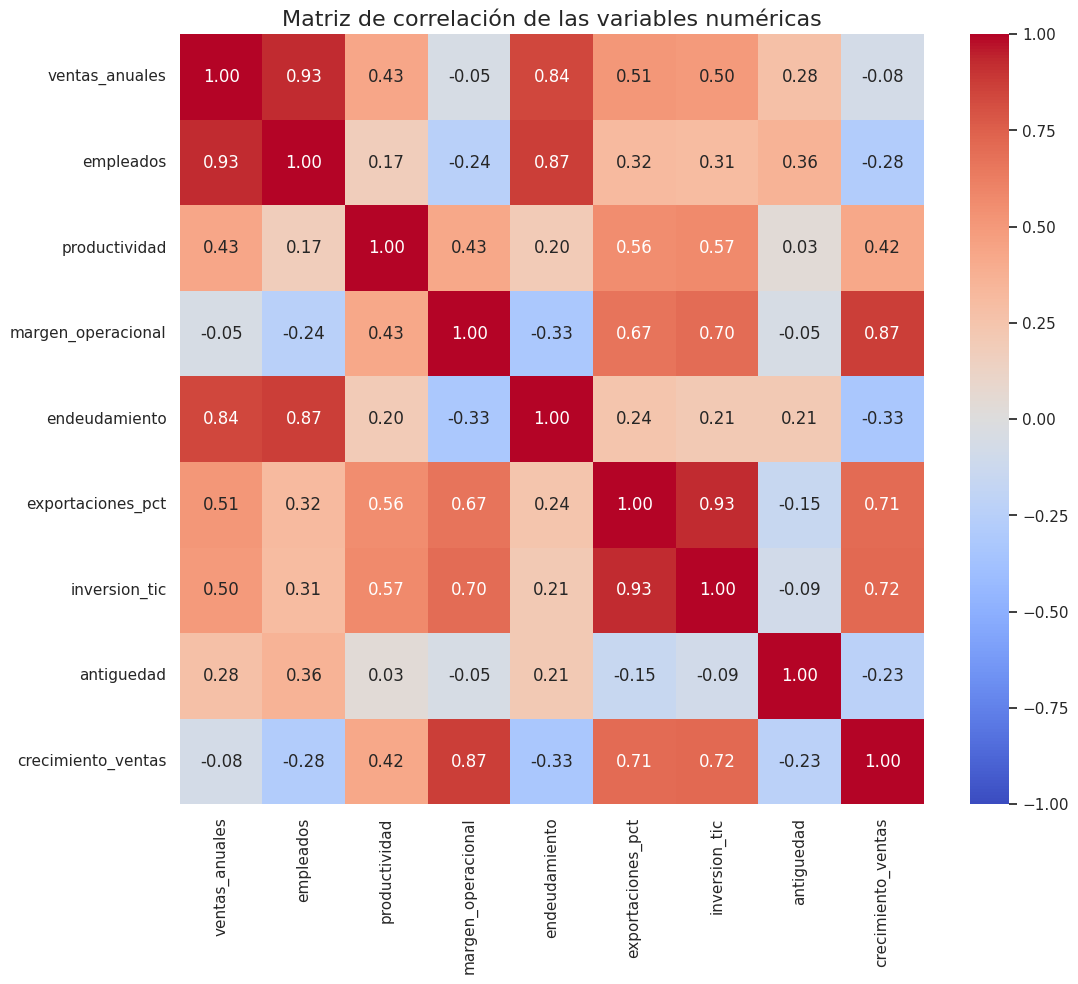

In [57]:
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(matriz_corr,
            ax=ax,                 # El eje sobre el cual graficar
            annot=True,            # Mostrar el valor de cada correlación
            fmt='.2f',             # Dos decimales
            cmap='coolwarm',       # Azul = correlación negativa, rojo = positiva
            vmin=-1, vmax=1)       # Escala completa de la correlación

ax.set_title('Matriz de correlación de las variables numéricas', fontsize=16)
plt.show()

**📝 A2. Lectura económica de las correlaciones** *(pregunta abierta)*

- ¿Cuál es el par de variables **más correlacionado positivamente**? ¿Tiene sentido económico?
- ¿Cuál es la correlación **negativa** más fuerte? ¿Qué historia cuenta sobre las empresas de la base?
- ¿Ves alguna pareja tan correlacionada que podrías sospechar redundancia? ¿Qué problema traería para el clustering?

In [58]:
analisis_correlaciones = """
El par más correlacionado positivamente es ventas_anuales con empleados, empatado con exportaciones_pct e inversion_tic, los dos con 0,93. Ambos tienen sentido económico. Una empresa que vende más necesita más trabajadores para producir, y las dos variables miden el tamaño de la empresa. En el otro caso, las empresas que invierten más en tecnología son más competitivas y pueden entrar más fácil a mercados externos.
La correlación negativa más fuerte es de -0,33 y se da entre endeudamiento y margen_operacional, y también entre endeudamiento y crecimiento_ventas. Esto muestra que las empresas más endeudadas son menos rentables y crecen menos. Como el endeudamiento también está muy relacionado con ventas y empleados, parece que en la base hay empresas grandes, endeudadas y estancadas, y otras más rentables que exportan, invierten en TIC y crecen más.
Sí hay parejas que podrían ser redundantes, como ventas y empleados o exportaciones e inversión en TIC. El problema es que en el clustering esa información contaría doble en la distancia y los grupos se formarían sobre todo por ella. Se puede solucionar dejando una sola variable de cada pareja o usando PCA.
"""

---
# ⚙️ **Ejercicio 3: Preprocesamiento y el efecto de la escala**

**3.1** Prepara los datos para el clustering:

1. Guarda en `X` **solo las nueve variables numéricas** (es decir, `df` sin `empresa`, `sector` ni `region`).
2. Crea un `StandardScaler` y guárdalo en una variable llamada `scaler` (lo vas a volver a necesitar en el Ejercicio 7).
3. Ajusta el `scaler` a `X` y guarda el resultado en `X_scaled`.
4. Imprime las 3 primeras filas de `X_scaled`.

In [63]:
X = df.drop(columns=['empresa', 'sector', 'region'])


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


print(X_scaled[:3])

[[-0.32215502 -0.01904015 -0.52760887 -0.08718771 -1.25608597 -0.58136218
  -0.33141033  1.59034862 -0.24214989]
 [-1.05399303 -1.01740016 -0.63255767 -0.32156328 -0.45632652 -0.72887165
  -0.56736155 -0.71945299 -0.66388602]
 [-0.32417792 -0.26863015 -0.00437858 -0.04582732 -0.07383287 -0.44477932
  -0.60106886  0.78693936  0.0420636 ]]


In [64]:
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
X_scaled_df.head(3)

,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
0,-0.32,-0.02,-0.53,-0.09,-1.26,-0.58,-0.33,1.59,-0.24
1,-1.05,-1.02,-0.63,-0.32,-0.46,-0.73,-0.57,-0.72,-0.66
2,-0.32,-0.27,-0.00,-0.05,-0.07,-0.44,-0.60,0.79,0.04


**3.2 ¿Y si no estandarizamos?** Vamos a comprobar con datos por qué el paso anterior no es opcional.

1. Guarda en `varianzas_sin_escalar` la **varianza de cada columna de `X`** (sin estandarizar), ordenada de mayor a menor. Imprímela.
2. Aplica K-Means **directamente sobre `X`, sin estandarizar**, con `n_clusters=5`, `init='k-means++'`, `n_init=10` y `random_state=42`. Guarda las etiquetas en `clusters_sin_escalar`.
3. Imprime cuántas empresas quedaron en cada grupo y el promedio de cada variable por grupo.

> El `k=5` de este punto es **provisional**: solo sirve para la comparación. En el Ejercicio 4 van a decidir el k de verdad.

In [65]:

varianzas_sin_escalar = X.var().sort_values(ascending=False)
print(varianzas_sin_escalar)

ventas_anuales       30,777,134.12
empleados                 3,158.95
productividad             1,577.51
exportaciones_pct           336.38
endeudamiento               298.94
crecimiento_ventas          119.45
antiguedad                   99.55
margen_operacional           52.82
inversion_tic                 8.84
dtype: float64


In [66]:

kmeans_sin_escalar = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=42)
clusters_sin_escalar = kmeans_sin_escalar.fit_predict(X)
clusters_sin_escalar

array([2, 1, 2, 3, 3, 2, 3, 1, 2, 0, 1, 1, 4, 1, 2, 1, 3, 4, 2, 1, 1, 1,
       4, 3, 1, 4, 1, 2, 2, 2, 1, 4, 1, 4, 3, 4, 2, 1, 1, 1, 3, 1, 3, 2,
       4, 2, 3, 4, 2, 1, 4, 2, 2, 2, 2, 2, 1, 1, 2, 2, 1, 1, 0, 1, 0, 4,
       4, 0, 1, 2, 2, 4, 2, 2, 1, 4, 4, 1, 0, 2, 2, 3, 2, 1, 2, 0, 1, 1,
       2, 2, 1, 1, 3, 0, 1, 2, 1, 2, 4, 4, 1, 1, 1, 4, 2, 1, 4, 1, 3, 2,
       2, 3, 2, 0, 2, 0, 4, 0, 3, 4, 3, 1, 4, 4, 2, 4, 2, 1, 4, 1, 3, 1,
       4, 2, 4, 4, 2, 3, 1, 4, 2, 1, 0, 2, 0, 2, 4, 1, 4, 2, 4, 4, 4, 2,
       1, 2, 2, 0, 4, 2, 1, 1, 4, 1, 0, 4, 4, 4, 2, 2, 1, 0, 1, 0, 0, 4,
       1, 2, 1, 1, 1, 0, 1, 1, 2, 0, 1, 1, 0, 1, 2, 4, 1, 0, 1, 2, 3, 1,
       4, 2, 2, 0, 2, 2, 4, 0, 1, 1, 1, 4, 2, 4, 0, 2, 1, 4, 1, 1, 1, 4,
       2, 2, 4, 4, 3, 1, 1, 2, 4, 1, 0, 1, 1, 3, 1, 2, 4, 2, 4, 1, 2, 1,
       2, 4, 2, 3, 1, 2, 2, 2], dtype=int32)

In [67]:
df['Cluster_sin_escalar'] = clusters_sin_escalar

print(df['Cluster_sin_escalar'].value_counts().sort_index())
df.groupby('Cluster_sin_escalar')[X.columns].mean()

Cluster_sin_escalar
0    25
1    79
2    72
3    21
4    53
Name: count, dtype: int64


,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
Cluster_sin_escalar,,,,,,,,,
0,"13,119.70",139.96,101.61,1.92,79.81,16.54,3.54,19.88,-3.28
1,361.92,6.42,67.86,4.61,39.46,0.45,0.63,7.34,2.25
2,"4,490.52",52.60,88.41,9.54,45.13,4.47,1.71,28.46,4.22
3,"17,568.06",177.05,101.01,-2.29,83.81,12.16,2.42,21.24,-10.13
4,"9,654.36",80.30,128.64,17.11,55.12,44.05,7.70,13.57,19.78


**📝 A3. El efecto de la escala** *(pregunta abierta)*

- ¿Qué variable concentra casi toda la varianza de `X` sin estandarizar? ¿Qué porcentaje de la varianza total representa?
- Mirando el perfil de los grupos de arriba: ¿qué variable está separando realmente a los grupos y cuáles está ignorando el algoritmo?
- Explica, con la fórmula de la distancia euclidiana en la cabeza, **por qué** ocurre esto.

In [68]:
analisis_escala = """
La variable que concentra casi toda la varianza es ventas_anuales, con cerca del 99,98% de la varianza total de X.
Los grupos se separan solo por ventas: cada grupo corresponde a un rango de tamaño (de unas 362 en el grupo 1 a 17.568 en el grupo 3). Variables como el margen, las exportaciones, la inversión en TIC, la antigüedad o el crecimiento las ignora el algoritmo.
Esto ocurre porque la distancia euclidiana suma las diferencias al cuadrado. Una diferencia de 1.000 en ventas aporta 1.000.000, mientras que una de 10 puntos en el margen aporta solo 100, así que las ventas dominan la distancia.


"""

---
# 📐 **Ejercicio 4: ¿Cuántos segmentos hay? (elección de k)**

De aquí en adelante **se trabaja siempre sobre `X_scaled`**.

**4.1 Método del codo.** Para cada `k` de **1 a 10**, entrena un K-Means sobre `X_scaled` (con `init='k-means++'`, `n_init=10`, `random_state=42`) y guarda su inercia en una lista llamada `wcss`. Grafica la curva.

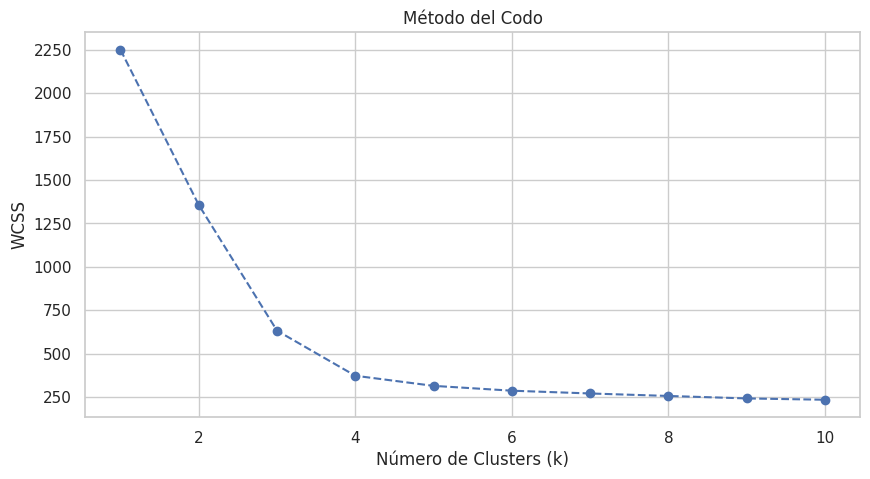

In [69]:
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Método del Codo')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('WCSS')
plt.show()

**📝 A4. Lectura del codo** *(pregunta abierta)*

¿Dónde está el "codo"? ¿Qué valores de k son candidatos razonables y cuáles quedan descartados? Apóyate en cuánto cae el WCSS al pasar de un k al siguiente.

In [70]:
analisis_codo = """
El codo está en k=4. Hasta ese punto el WCSS cae bastante (unos 900 de k=1 a 2, 720 de 2 a 3 y 260 de 3 a 4), pero de 4 a 5 solo baja unos 55 y después menos. Los candidatos razonables son k=3 y k=4. Se descartan k=1 y k=2 porque todavía falta mucha reducción del WCSS, y de k=5 en adelante porque la mejora es mínima.
"""

**4.2 Coeficiente de silueta.** Para cada `k` de **2 a 10**, entrena un K-Means sobre `X_scaled` (con `n_init=10` y `random_state=42`), calcula el `silhouette_score` y guárdalo en una lista llamada `silhouette_scores`. Imprime el valor de cada k y grafica la curva.

Para n_clusters = 2, el coeficiente de silueta promedio es: 0.4530
Para n_clusters = 3, el coeficiente de silueta promedio es: 0.5826
Para n_clusters = 4, el coeficiente de silueta promedio es: 0.5568
Para n_clusters = 5, el coeficiente de silueta promedio es: 0.5555
Para n_clusters = 6, el coeficiente de silueta promedio es: 0.4697
Para n_clusters = 7, el coeficiente de silueta promedio es: 0.3854
Para n_clusters = 8, el coeficiente de silueta promedio es: 0.3031
Para n_clusters = 9, el coeficiente de silueta promedio es: 0.2211
Para n_clusters = 10, el coeficiente de silueta promedio es: 0.2286


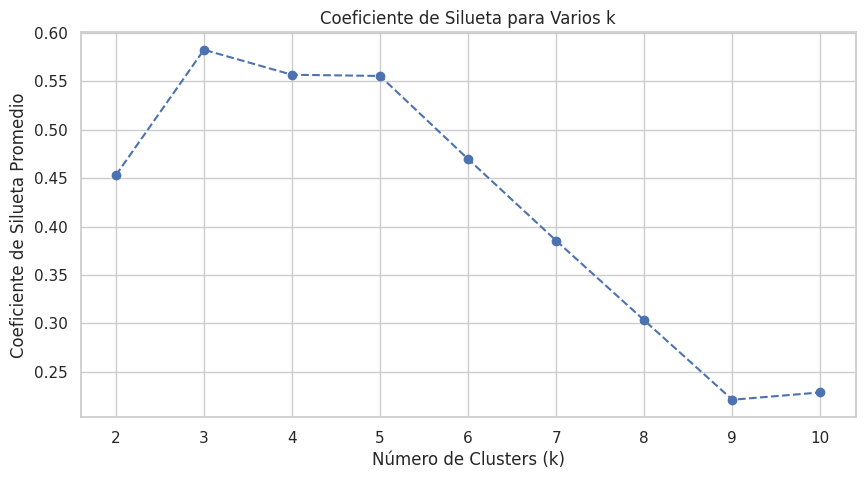

In [71]:
range_n_clusters = range(2, 11)

silhouette_scores = []

for n_clusters in range_n_clusters:
    clusterer = KMeans(n_clusters=n_clusters, n_init=10, random_state=42)
    cluster_labels = clusterer.fit_predict(X_scaled)
    silhouette_avg = silhouette_score(X_scaled, cluster_labels)
    silhouette_scores.append(silhouette_avg)
    print(f"Para n_clusters = {n_clusters}, el coeficiente de silueta promedio es: {silhouette_avg:.4f}")

plt.figure(figsize=(10, 5))
plt.plot(range_n_clusters, silhouette_scores, marker='o', linestyle='--')
plt.title('Coeficiente de Silueta para Varios k')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Coeficiente de Silueta Promedio')
plt.show()

**📝 A5. Lectura de la silueta** *(pregunta abierta)*

¿Qué k maximiza el coeficiente de silueta? ¿Qué significa ese número (recuerda: cohesión y separación)? ¿El resultado **coincide** con el del método del codo o hay tensión entre los dos criterios?

In [ ]:
analisis_silueta = """
El k que maximiza el coeficiente de silueta es 3, con un valor de 0,58. esto quiere decir que en promedio las empresas están más cerca de las de su mismo grupo que de las del grupo más cercano, o sea que hay buena cohesión y separación. como el valor es positivo y más cercano a 1 que a 0, los grupos están bien definidos.
El resultado no coincide del todo con el método del codo, que daba k4. Pero la diferencia es pequeña, porque con k=4 la silueta es de 0,56 casi lo mismo que con k=3. entonces los dos métodos indican que el número de grupos está entre 3 y 4.
"""

**4.3 La decisión.** Con el codo y la silueta sobre la mesa, **tu equipo decide**: guarda en `k_optimo` el número de clusters que van a usar en el resto del taller.

> La verificación automática **acepta cualquier k razonable**; lo que se califica aquí es la **justificación**, no el número.

In [72]:
k_optimo = 4

print("El equipo trabajará con k =", k_optimo)

El equipo trabajará con k = 4


**📝 A6. Justificación del k elegido** *(pregunta abierta)*

Justifiquen la decisión. No basta con decir "porque la silueta es más alta": expliquen cómo pesaron los dos criterios estadísticos **y** el criterio de utilidad para el cliente (¿cuántos programas distintos puede administrar razonablemente Bancóldex?).

In [ ]:
justificacion_k = """
Escogimos k=4 porque es el punto donde está el codo, es decir, el último k en el que agregar un cluster reduce bastante el WCSS. aunque la silueta más alta es con k=3 0,58 con k=4 es de 0,56 así que la diferencia es muy pequeña y los grupos siguen estando bien definidos. con k=4 tenemos un grupo más para diferenciar los perfiles de empresas sin perder casi nada en cohesión y separación.
"""

---
# 🎯 **Ejercicio 5: K-Means, perfilamiento e interpretación**

**5.1** Entrena el modelo definitivo:

1. Crea un `KMeans` con `n_clusters=k_optimo`, `init='k-means++'`, `n_init=10` y `random_state=42`, y guárdalo en una variable llamada `kmeans`.
2. Ajústalo sobre `X_scaled` y añade las etiquetas a `df` en una columna nueva llamada `cluster_kmeans`.
3. Imprime cuántas empresas quedaron en cada segmento y qué porcentaje del total representan.

In [73]:
kmeans = KMeans(n_clusters=k_optimo, init='k-means++', n_init=10, random_state=42)

df['cluster_kmeans'] = kmeans.fit_predict(X_scaled)
df

,empresa,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas,sector,region,Cluster_sin_escalar,cluster_kmeans
0,PYME_001,"4,458.40",62,71.91,7.20,30.50,2.80,1.90,33,2.30,Comercio,Andina,2,0
1,PYME_002,406.50,6,67.75,5.50,44.30,0.10,1.20,10,-2.30,Comercio,Eje Cafetero,1,3
2,PYME_003,"4,447.20",48,92.65,7.50,50.90,5.30,1.10,25,5.40,Comercio,Andina,2,0
3,PYME_004,"16,455.90",119,138.28,-1.20,77.30,13.80,2.60,28,-8.00,Comercio,Pacífica,3,1
4,PYME_005,"16,413.80",203,80.86,-3.50,84.20,4.90,2.40,18,-14.50,Servicios,Andina,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
245,PYME_246,"19,804.30",183,108.22,1.60,85.20,11.00,2.00,22,-16.40,Manufactura,Andina,3,1
246,PYME_247,410.50,2,205.25,2.30,32.50,0.30,0.30,1,-0.60,Agroindustria,Pacífica,1,3
247,PYME_248,"4,339.20",46,94.33,5.00,43.40,5.70,0.90,33,7.80,Comercio,Andina,2,0
248,PYME_249,"5,574.30",64,87.10,11.00,48.10,1.10,2.20,24,1.30,Manufactura,Pacífica,2,0


In [75]:
conteo = df['cluster_kmeans'].value_counts().sort_index()
porcentaje = df['cluster_kmeans'].value_counts(normalize=True).sort_index() * 100

print(pd.DataFrame({'empresas': conteo, 'porcentaje (%)': porcentaje}))

                empresas  porcentaje (%)
cluster_kmeans                          
0                     71           28.40
1                     44           17.60
2                     57           22.80
3                     78           31.20


**5.2** Construye el **perfil** de los segmentos: guarda en `perfil_clusters` el **promedio de cada variable numérica** para cada cluster (las nueve variables de `X`, agrupadas por `cluster_kmeans`). Muéstralo.

In [76]:
perfil_clusters = df.groupby('cluster_kmeans')[X.columns].mean()
perfil_clusters

,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
cluster_kmeans,,,,,,,,,
0,"4,402.50",51.90,87.87,9.29,44.85,3.26,1.58,29.00,3.81
1,"15,201.51",165.82,93.39,-2.35,84.18,11.78,2.36,21.73,-9.96
2,"9,696.40",75.95,132.31,18.38,54.09,45.26,8.02,12.67,21.55
3,338.11,5.86,68.16,4.54,39.38,0.39,0.61,7.10,2.24


**5.3** Evalúa y visualiza la solución final:

1. Guarda en `silueta_final` el `silhouette_score` del modelo definitivo (calculado sobre `X_scaled` y la columna `cluster_kmeans`). Imprímelo.
2. Guarda en `centroides_originales` los centroides **devueltos a las unidades originales**, usando `scaler.inverse_transform(...)` sobre `kmeans.cluster_centers_`.
3. Haz un *scatter plot* de `exportaciones_pct` (eje X) contra `margen_operacional` (eje Y), coloreando por `cluster_kmeans`, y marca encima los centroides con una `X` roja grande.

> Pista para el gráfico: `centroides_originales` tiene las columnas en el mismo orden que `X`, así que `exportaciones_pct` es la columna 5 y `margen_operacional` la columna 3.

In [77]:
silueta_final = silhouette_score(X_scaled, df['cluster_kmeans'])
print(f"El coeficiente de silueta del modelo final es: {silueta_final:.4f}")

centroides_originales = scaler.inverse_transform(kmeans.cluster_centers_)
centroides_originales

El coeficiente de silueta del modelo final es: 0.5568


array([[ 4.40250141e+03,  5.19014085e+01,  8.78726761e+01,
         9.29014085e+00,  4.48521127e+01,  3.26478873e+00,
         1.58169014e+00,  2.90000000e+01,  3.80845070e+00],
       [ 1.52015136e+04,  1.65818182e+02,  9.33904545e+01,
        -2.35000000e+00,  8.41818182e+01,  1.17795455e+01,
         2.35909091e+00,  2.17272727e+01, -9.95909091e+00],
       [ 9.69639649e+03,  7.59473684e+01,  1.32305614e+02,
         1.83824561e+01,  5.40912281e+01,  4.52578947e+01,
         8.01578947e+00,  1.26666667e+01,  2.15526316e+01],
       [ 3.38111538e+02,  5.85897436e+00,  6.81580769e+01,
         4.53974359e+00,  3.93820513e+01,  3.91025641e-01,
         6.12820513e-01,  7.10256410e+00,  2.23846154e+00]])

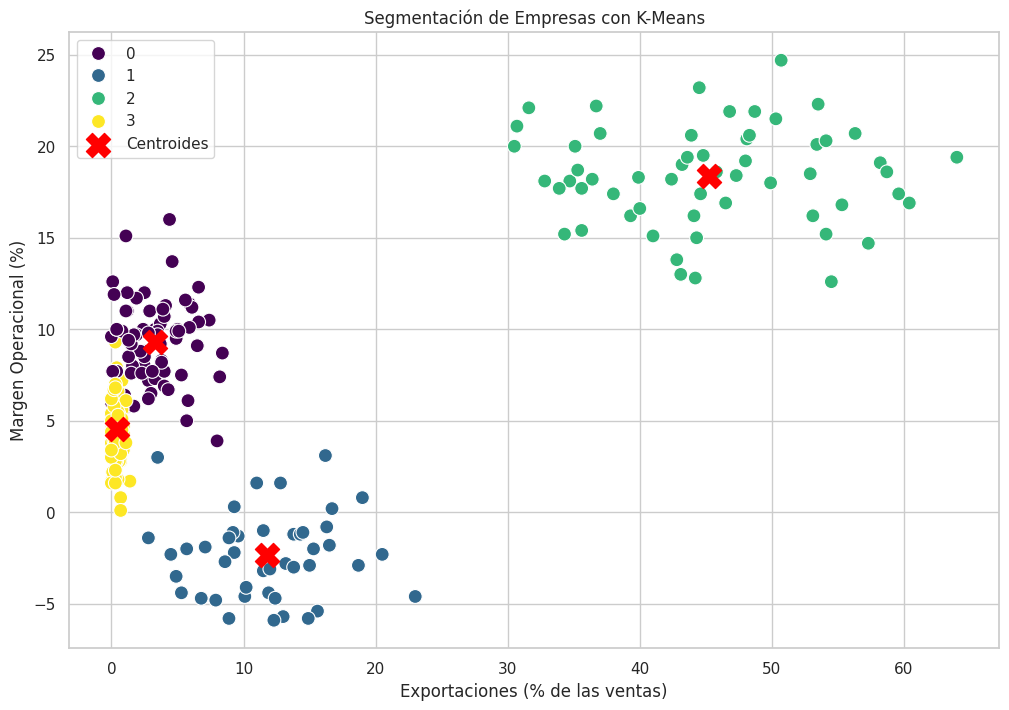

In [78]:
plt.figure(figsize=(12, 8))
sns.scatterplot(x='exportaciones_pct', y='margen_operacional', hue='cluster_kmeans', data=df, palette='viridis', s=100)

plt.scatter(centroides_originales[:, 5], centroides_originales[:, 3], s=300, c='red', marker='X', label='Centroides')

plt.title('Segmentación de Empresas con K-Means')
plt.xlabel('Exportaciones (% de las ventas)')
plt.ylabel('Margen Operacional (%)')
plt.legend()
plt.show()

**5.4 Visualización complementaria.** Haz un segundo gráfico que te ayude a contar la historia: por ejemplo un `boxplot` de `endeudamiento` por cluster, o un *scatter* de `productividad` contra `crecimiento_ventas`.

*(Este punto no tiene prueba automática: se evalúa junto con el análisis escrito.)*

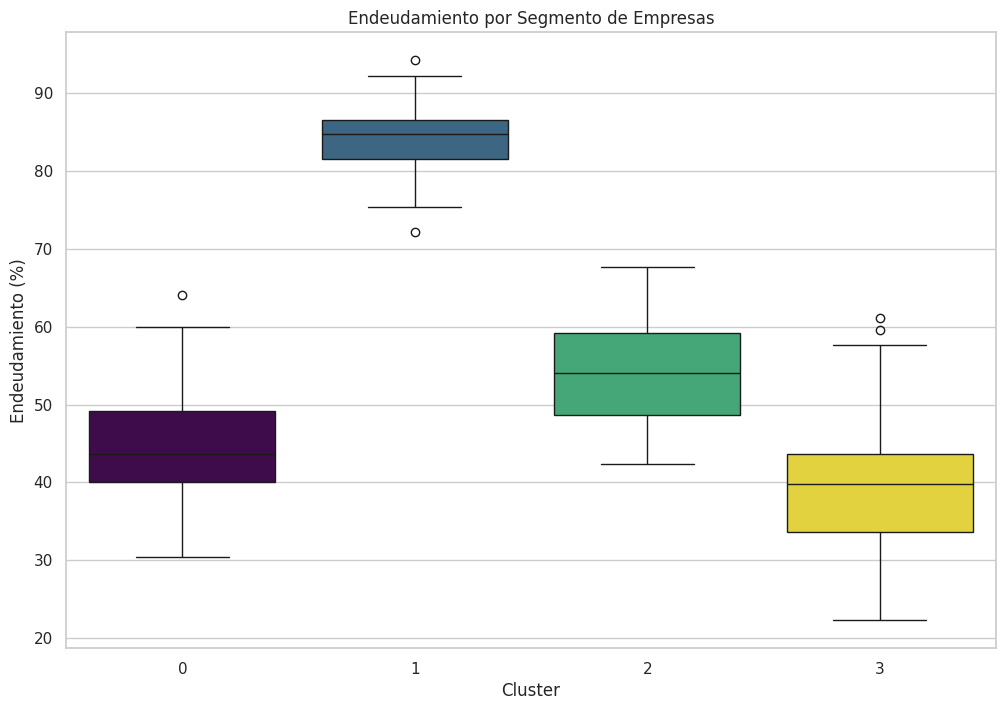

In [79]:
plt.figure(figsize=(12, 8))
sns.boxplot(x='cluster_kmeans', y='endeudamiento', hue='cluster_kmeans', data=df, palette='viridis', legend=False)

plt.title('Endeudamiento por Segmento de Empresas')
plt.xlabel('Cluster')
plt.ylabel('Endeudamiento (%)')
plt.show()

**📝 A7. Nombra los segmentos** *(pregunta abierta)*

Guarda en `nombres_clusters` una **lista de textos** con un nombre descriptivo para cada segmento, **en el orden de los clusters** (posición 0 = cluster 0, posición 1 = cluster 1, …). Deben ser tantos nombres como clusters elegiste.

Un buen nombre le dice al cliente qué es el grupo sin necesidad de mirar la tabla. En una segmentación de clientes de un banco, por ejemplo, *"Jóvenes con alta rotación de tarjeta"* es un buen nombre y *"Grupo 1"* no lo es.

In [80]:
nombres_clusters = [
  "Medianas tradicionales enfocadas en el mercado interno",
    "Grandes sobreendeudadas y en contracción",
    "Exportadoras tecnológicas de alto crecimiento",
    "Microempresas jóvenes de baja productividad"
    # agrega tantos nombres como clusters hayas elegido
]

for i, nombre in enumerate(nombres_clusters):
    print("Cluster %d: %s" % (i, nombre))

Cluster 0: Medianas tradicionales enfocadas en el mercado interno
Cluster 1: Grandes sobreendeudadas y en contracción
Cluster 2: Exportadoras tecnológicas de alto crecimiento
Cluster 3: Microempresas jóvenes de baja productividad


**📝 A8. Describe cada segmento** *(pregunta abierta)*

Para **cada** cluster, describe su perfil económico apoyándote en `perfil_clusters`: tamaño (ventas y empleados), productividad, rentabilidad, endeudamiento, vocación exportadora, inversión en tecnología, antigüedad y crecimiento. Menciona también **cuántas empresas** tiene y **qué porcentaje** del total representa.

Cierra con una frase por segmento: *¿cuál es el principal problema o la principal oportunidad de este grupo?*

In [81]:
descripcion_clusters = """
cluster 0:Tiene 71 empresas, el 28,4% del total. Son empresas medianas, con ventas promedio de 4.403 y unos 52 empleados. Su productividad de 87,9 está por debajo del promedio de la base, tienen un margen operacional del 9,3% y un endeudamiento moderado de 44,9%. Casi no exportan e invierten poco en TIC. Son las más antiguas, con 29 años en promedio, y crecen a un ritmo bajo de 3,8%. Su principal problema es que están estancadas, son estables pero no se modernizan ni buscan mercados externos.
cluster 1:Tiene 44 empresas, el 17,6% del total. Son las empresas más grandes, con ventas promedio de 15.202 y unos 166 empleados. Su productividad de 93,4 es parecida al promedio de la base, pero tienen un margen operacional negativo de -2,35% y un endeudamiento muy alto de 84,2%. Exportan el 11,8% de sus ventas e invierten poco en TIC. Tienen unos 22 años en promedio y sus ventas caen casi 10%. Su principal problema es que tienen pérdidas y mucha deuda, entonces corren riesgo de no poder pagar.
cluster 2:Tiene 57 empresas, el 22,8% del total. Son empresas medianas grandes, con ventas promedio de 9.696 y unos 76 empleados. Tienen la productividad más alta de la base con 132,3, el mejor margen operacional con 18,4% y un endeudamiento de 54,1%. Exportan el 45,3% de sus ventas y son las que más invierten en TIC. Son relativamente jóvenes, con unos 13 años en promedio, y crecen 21,6%. Su principal oportunidad es seguir creciendo en mercados externos, porque son el grupo más competitivo.
cluster 3:Tiene 78 empresas, el 31,2% del total, y es el grupo más grande. Son microempresas, con ventas promedio de 338 y unos 6 empleados. Tienen la productividad más baja de la base con 68,2, un margen operacional del 4,5% y el menor endeudamiento con 39,4%. Casi no exportan ni invierten en TIC. Son las más jóvenes, con 7 años en promedio, y crecen 2,2%. Su principal problema es que no logran crecer, probablemente por falta de acceso a crédito y tecnología.
"""

---
# 🧩 **Ejercicio 6: ¿Y el sector? Clustering con variables mixtas (K-Prototypes)**

Hasta aquí dejamos por fuera `sector`, porque K-Means solo entiende números y la distancia euclidiana no sabe qué tan "lejos" está *Agroindustria* de *TIC*.

**K-Prototypes** resuelve el problema: usa la **media** como prototipo de las variables numéricas y la **moda** de las categóricas, y combina la distancia euclidiana con la distancia de Hamming.

In [82]:
!pip install kmodes --quiet

In [83]:
from kmodes.kprototypes import KPrototypes
from sklearn.preprocessing import LabelEncoder

**6.1** Prepara los datos mixtos. Sigue **exactamente** este orden de columnas, porque el algoritmo trabaja por posición:

1. Crea `df_mixto` como una copia de `df` con las **nueve variables numéricas de `X`** y, **al final**, la columna `sector`. (Es decir, 10 columnas en total, con `sector` en la última posición.)
2. Guarda en `indice_categoricas` la lista con la posición de la columna categórica dentro de `df_mixto`.
3. Convierte `df_mixto` a una matriz de NumPy y guárdala en `matriz_mixta`.
4. Estandariza **solo las nueve columnas numéricas** de `matriz_mixta` (posiciones 0 a 8), usando un `StandardScaler` **nuevo** (no reutilices `scaler`, que lo necesitas intacto para el Ejercicio 7).
5. Codifica la columna `sector` de `matriz_mixta` con `LabelEncoder`.
6. Imprime las 3 primeras filas de `matriz_mixta`.

In [84]:
df_mixto = df[list(X.columns) + ['sector']].copy()
df_mixto

,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas,sector
0,"4,458.40",62,71.91,7.20,30.50,2.80,1.90,33,2.30,Comercio
1,406.50,6,67.75,5.50,44.30,0.10,1.20,10,-2.30,Comercio
2,"4,447.20",48,92.65,7.50,50.90,5.30,1.10,25,5.40,Comercio
3,"16,455.90",119,138.28,-1.20,77.30,13.80,2.60,28,-8.00,Comercio
4,"16,413.80",203,80.86,-3.50,84.20,4.90,2.40,18,-14.50,Servicios
...,...,...,...,...,...,...,...,...,...,...
245,"19,804.30",183,108.22,1.60,85.20,11.00,2.00,22,-16.40,Manufactura
246,410.50,2,205.25,2.30,32.50,0.30,0.30,1,-0.60,Agroindustria
247,"4,339.20",46,94.33,5.00,43.40,5.70,0.90,33,7.80,Comercio
248,"5,574.30",64,87.10,11.00,48.10,1.10,2.20,24,1.30,Manufactura


In [85]:
indice_categoricas = [9]

matriz_mixta = df_mixto.values

scaler_mixto = StandardScaler()
matriz_mixta[:, 0:9] = scaler_mixto.fit_transform(matriz_mixta[:, 0:9])

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
matriz_mixta[:, 9] = le.fit_transform(matriz_mixta[:, 9])
print(f"El mapeo de clases es: {le.classes_}")

print(matriz_mixta[:3])

El mapeo de clases es: ['Agroindustria' 'Comercio' 'Manufactura' 'Servicios' 'TIC']
[[-0.32215502244818983 -0.019040151619805316 -0.5276088744673821
  -0.0871877106365195 -1.256085972320208 -0.5813621752210532
  -0.3314103334258739 1.5903486182423119 -0.2421498859617228 1]
 [-1.0539930303588514 -1.0174001616470525 -0.6325576693059609
  -0.3215632768637223 -0.45632651776549416 -0.7288716547061528
  -0.5673615472156539 -0.7194529869340696 -0.6638860193192588 1]
 [-0.3241779217518744 -0.26863015412661706 -0.004378584815428655
  -0.04582731659642492 -0.07383286558715263 -0.4447793238459608
  -0.6010688634713367 0.7869393642679183 0.04206359521400809 1]]


**6.2** Aplica K-Prototypes con el **mismo `k_optimo`** que elegiste, usando `init='Cao'`, `n_init=5`, `verbose=0` y `random_state=42`. Guarda el modelo en `kproto` y las etiquetas en una columna nueva de `df` llamada `cluster_kproto`.

*(Este punto no tiene prueba automática, porque el resultado de `kmodes` puede variar entre versiones. Se evalúa con el análisis escrito.)*

In [86]:
from kmodes.kprototypes import KPrototypes

kproto = KPrototypes(n_clusters=k_optimo, init='Cao', n_init=5, verbose=0, random_state=42)
clusters_kproto = kproto.fit_predict(matriz_mixta, categorical=indice_categoricas)

df['cluster_kproto'] = clusters_kproto
df

,empresa,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas,sector,region,Cluster_sin_escalar,cluster_kmeans,cluster_kproto
0,PYME_001,"4,458.40",62,71.91,7.20,30.50,2.80,1.90,33,2.30,Comercio,Andina,2,0,1
1,PYME_002,406.50,6,67.75,5.50,44.30,0.10,1.20,10,-2.30,Comercio,Eje Cafetero,1,3,0
2,PYME_003,"4,447.20",48,92.65,7.50,50.90,5.30,1.10,25,5.40,Comercio,Andina,2,0,1
3,PYME_004,"16,455.90",119,138.28,-1.20,77.30,13.80,2.60,28,-8.00,Comercio,Pacífica,3,1,3
4,PYME_005,"16,413.80",203,80.86,-3.50,84.20,4.90,2.40,18,-14.50,Servicios,Andina,3,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
245,PYME_246,"19,804.30",183,108.22,1.60,85.20,11.00,2.00,22,-16.40,Manufactura,Andina,3,1,3
246,PYME_247,410.50,2,205.25,2.30,32.50,0.30,0.30,1,-0.60,Agroindustria,Pacífica,1,3,0
247,PYME_248,"4,339.20",46,94.33,5.00,43.40,5.70,0.90,33,7.80,Comercio,Andina,2,0,1
248,PYME_249,"5,574.30",64,87.10,11.00,48.10,1.10,2.20,24,1.30,Manufactura,Pacífica,2,0,1


**6.3** Compara las dos segmentaciones:

1. Guarda en `comparacion` una tabla cruzada (`pd.crosstab`) entre `cluster_kmeans` y `cluster_kproto`. Muéstrala.
2. Muestra también el perfil de los clusters de K-Prototypes: el promedio de las variables numéricas y la **moda** de `sector` para cada grupo.

In [87]:
comparacion = pd.crosstab(df['cluster_kmeans'], df['cluster_kproto'])
comparacion

cluster_kproto,0,1,2,3
cluster_kmeans,,,,
0,0,71,0,0
1,0,0,0,44
2,0,0,57,0
3,78,0,0,0


In [88]:
print("\nPerfil de los clusters (medias y modas):")

agregaciones = {col: 'mean' for col in X.columns}
agregaciones['sector'] = lambda x: x.mode()[0]

df.groupby('cluster_kproto').agg(agregaciones).round(2)


Perfil de los clusters (medias y modas):


,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas,sector
cluster_kproto,,,,,,,,,,
0,338.11,5.86,68.16,4.54,39.38,0.39,0.61,7.10,2.24,Comercio
1,"4,402.50",51.90,87.87,9.29,44.85,3.26,1.58,29.00,3.81,Manufactura
2,"9,696.40",75.95,132.31,18.38,54.09,45.26,8.02,12.67,21.55,TIC
3,"15,201.51",165.82,93.39,-2.35,84.18,11.78,2.36,21.73,-9.96,Manufactura


**📝 A9. ¿Qué aporta incluir el sector?** *(pregunta abierta)*

- Mirando `comparacion`: ¿los dos algoritmos encontraron prácticamente los mismos grupos o cambiaron de forma importante?
- ¿Qué **añade** (o qué **no** añade) la variable `sector` a la segmentación? ¿Por qué crees que ocurre eso con esta base en particular?
- ¿En qué situación de negocio **sí** valdría la pena usar K-Prototypes en lugar de K-Means?

In [89]:
analisis_kprototypes = """
Los dos algoritmos encontraron los mismos grupos. En la tabla cruzada cada cluster de K-Means queda completo en un solo cluster de K-Prototypes, lo único que cambia es el número. Por ejemplo, el cluster 3 de K-Means, que son las microempresas, es el cluster 0 de K-Prototypes, y los promedios son iguales.
El sector no cambió los grupos, solo ayuda a describirlos. En las microempresas el sector más común es Comercio, en las exportadoras tecnológicas es TIC y en las medianas tradicionales y las grandes endeudadas es Manufactura. Esto pasa porque las variables numéricas ya separan muy bien a las empresas y el sector es solo una variable frente a nueve, entonces pesa poco en la distancia. Además, el sector va de la mano con los perfiles numéricos, por ejemplo las empresas TIC son las que más invierten en tecnología y más exportan, así que no aporta algo nuevo.
K-Prototypes sí valdría la pena cuando las variables categóricas son importantes y no se reflejan en las numéricas. Por ejemplo, un banco que quiera segmentar a sus clientes por ingreso y saldo, pero también por ciudad o por el canal que usan, o el gobierno si necesita grupos de empresas que sean del mismo sector para diseñar una política sectorial.
"""

---
# 🏢 **Ejercicio 7: Poner el modelo a trabajar**

Bancóldex acaba de recibir tres solicitudes nuevas. Necesitan saber **a qué segmento pertenece cada una** para dirigirlas al programa correcto, sin volver a correr todo el análisis.

In [90]:
# Las tres empresas que acaban de postularse (ejecutar sin modificar)
nuevas_empresas = pd.DataFrame(
    {
        'ventas_anuales':     [11200.0,   280.0, 17800.0],
        'empleados':          [     68,       5,     171],
        'productividad':      [ 164.71,   56.00,  104.09],
        'margen_operacional': [   19.4,     3.8,    -3.1],
        'endeudamiento':      [   49.5,    36.2,    88.7],
        'exportaciones_pct':  [   52.0,     0.0,     9.8],
        'inversion_tic':      [    8.6,     0.5,     2.0],
        'antiguedad':         [     11,       6,      24],
        'crecimiento_ventas': [   24.5,     1.9,   -11.2],
    },
    index=['Solicitud A', 'Solicitud B', 'Solicitud C'],
)
nuevas_empresas

,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
Solicitud A,"11,200.00",68,164.71,19.40,49.50,52.00,8.60,11,24.50
Solicitud B,280.00,5,56.00,3.80,36.20,0.00,0.50,6,1.90
Solicitud C,"17,800.00",171,104.09,-3.10,88.70,9.80,2.00,24,-11.20


**7.1** Clasifica las tres solicitudes:

1. Estandariza `nuevas_empresas` con el `scaler` **que ya entrenaste** en el Ejercicio 3 y guarda el resultado en `nuevas_scaled`.
2. Usa `kmeans.predict(...)` para obtener el cluster de cada una y guárdalo en `clusters_nuevas`.
3. Imprime, para cada solicitud, el cluster asignado y el nombre que le pusiste a ese segmento en `nombres_clusters`.

> ⚠️ **Trampa clásica:** aquí se usa `scaler.transform(...)`, **no** `fit_transform(...)`. Piensa por qué: si vuelves a ajustar el escalador con tres empresas, estarías midiéndolas contra el promedio de esas tres y no contra el de las 250 de la base.

In [91]:
nuevas_scaled = scaler.transform(nuevas_empresas)
clusters_nuevas = kmeans.predict(nuevas_scaled)

for solicitud, cluster in zip(nuevas_empresas.index, clusters_nuevas):
    print(f"{solicitud}: Cluster {cluster} - {nombres_clusters[cluster]}")

Solicitud A: Cluster 2 - Exportadoras tecnológicas de alto crecimiento
Solicitud B: Cluster 3 - Microempresas jóvenes de baja productividad
Solicitud C: Cluster 1 - Grandes sobreendeudadas y en contracción


**📝 A10. Recomendaciones de política** *(pregunta abierta)*

Guarda en `recomendaciones` una **lista de textos**, una recomendación por segmento. Cada una debe decir:

- a **qué segmento** va dirigida,
- **qué instrumento** concreto propones (línea de crédito, garantía, subsidio, asistencia técnica, programa de internacionalización, reestructuración de pasivos…),
- **por qué ese instrumento y no otro**, citando los números del perfil del grupo,
- **qué indicador** usarías para saber si funcionó.

In [92]:
recomendaciones = [
    "Cluster 0, Medianas tradicionales enfocadas en el mercado interno: proponemos asistencia técnica "
    "para modernización tecnológica junto con una línea de crédito para inversión en TIC. Estas empresas "
    "son rentables, con un margen del 9,3%, y su endeudamiento de 44,9% es moderado, así que pueden asumir "
    "deuda. Su problema es que solo invierten 1,6 en TIC, exportan el 3,3% y crecen 3,8%, entonces lo que "
    "les falta es modernizarse para volverse más productivas. El indicador para saber si funcionó sería "
    "el aumento de la productividad y de la inversión en TIC.",

    "Cluster 1, Grandes sobreendeudadas y en contracción: proponemos un programa de reestructuración de "
    "pasivos y no un crédito nuevo. Estas empresas tienen un endeudamiento de 84,2%, margen negativo de "
    "-2,35% y sus ventas caen 9,96%, así que darles más deuda solo aumentaría el riesgo de que no puedan "
    "pagar. Lo que necesitan es ampliar plazos y bajar la carga financiera para recuperar su operación. "
    "El indicador sería la reducción del endeudamiento y que el margen operacional vuelva a ser positivo.",

    "Cluster 2, Exportadoras tecnológicas de alto crecimiento: proponemos un programa de internacionalización "
    "con financiamiento para comercio exterior. Son las empresas más competitivas, con la productividad más "
    "alta de 132,3, margen de 18,4%, exportan el 45,3% de sus ventas y crecen 21,6%. No necesitan subsidios "
    "sino apoyo para llegar a más mercados. El indicador sería el crecimiento de las exportaciones y del "
    "número de mercados a los que venden.",

    "Cluster 3, Microempresas jóvenes de baja productividad: proponemos garantías para acceso a crédito "
    "junto con asistencia técnica. Son el grupo más grande con 78 empresas, venden apenas 338, tienen la "
    "productividad más baja de 68,2 y casi no invierten en TIC. Su endeudamiento de 39,4% es el más bajo, "
    "lo que sugiere que no tienen acceso a crédito más que falta de necesidad, por eso una garantía les "
    "facilita que los bancos les presten. El indicador sería el acceso a crédito formal y el aumento de "
    "las ventas y la productividad.",
]


for r in recomendaciones:
    print("-", r)

- Cluster 0, Medianas tradicionales enfocadas en el mercado interno: proponemos asistencia técnica para modernización tecnológica junto con una línea de crédito para inversión en TIC. Estas empresas son rentables, con un margen del 9,3%, y su endeudamiento de 44,9% es moderado, así que pueden asumir deuda. Su problema es que solo invierten 1,6 en TIC, exportan el 3,3% y crecen 3,8%, entonces lo que les falta es modernizarse para volverse más productivas. El indicador para saber si funcionó sería el aumento de la productividad y de la inversión en TIC.
- Cluster 1, Grandes sobreendeudadas y en contracción: proponemos un programa de reestructuración de pasivos y no un crédito nuevo. Estas empresas tienen un endeudamiento de 84,2%, margen negativo de -2,35% y sus ventas caen 9,96%, así que darles más deuda solo aumentaría el riesgo de que no puedan pagar. Lo que necesitan es ampliar plazos y bajar la carga financiera para recuperar su operación. El indicador sería la reducción del endeuda

**📝 A11. Limitaciones del análisis** *(pregunta abierta)*

Antes de entregarle esto a un cliente hay que ser honesto sobre lo que el método **no** puede decir. Discute al menos cuatro limitaciones. Algunas pistas:

- ¿Qué supone K-Means sobre la **forma** de los grupos?
- ¿Qué pasa con las empresas que quedan **en la frontera** entre dos clusters?
- ¿Los segmentos que encontraste son un **hecho** de la economía colombiana o un **resultado** de las variables que te dieron y del k que elegiste?
- ¿Puedes concluir que el endeudamiento **causa** la caída de las ventas?
- ¿Qué pasaría si repitieras el ejercicio el año entrante?

In [93]:
limitaciones = """
K-Means supone que los grupos son compactos y más o menos esféricos. Si en la realidad tienen otra forma o tamaños muy distintos, el algoritmo los puede partir o juntar mal.
Las empresas que están en la frontera entre dos clusters se asignan a uno solo, aunque se parezcan casi igual a los dos. El método no dice qué tan segura es esa asignación, entonces la política pensada para su grupo podría no servirles.
Los segmentos no son un hecho de la economía colombiana, dependen de las variables que nos dieron, de la muestra de 250 empresas y del k que elegimos. Con otras variables o con k=3 los grupos podrían cambiar.
No se puede decir que el endeudamiento cause la caída de las ventas. El clustering solo muestra que las dos cosas aparecen juntas en el cluster 1, pero podría ser al revés, que las empresas se endeudan porque venden menos.
Si se repite el ejercicio el próximo año, los grupos podrían ser distintos, porque es una foto de un solo momento. Por eso la segmentación habría que actualizarla cada cierto tiempo.
"""

**📝 A12. ¿Cómo validarías los segmentos con el cliente?** *(pregunta abierta)*

Un clustering estadísticamente impecable puede ser inútil en la práctica. Antes de que Bancóldex rediseñe sus programas, ¿cómo comprobarías que estos segmentos sirven? Piensa en:

- evidencia adicional que pedirías (otras variables, otros años, opinión de los analistas de crédito);
- alguna prueba **cuantitativa** que se pueda hacer con los datos;
- cómo harías el piloto antes de escalar el programa a todo el país.

In [94]:
validacion_negocio = """
Pediría datos de otros años para ver si los grupos se mantienen, variables como la morosidad o la región, y la opinión de los analistas de crédito para saber si los segmentos coinciden con lo que ellos ven.
Como prueba cuantitativa, correría el K-Means con distintas semillas o submuestras para ver si las empresas siguen quedando en los mismos grupos.
Para el piloto, a una parte de las empresas de cada segmento, escogida al azar, le daría el programa y a la otra no. Si las que lo recibieron mejoran frente a las demás, se escala a todo el país.
"""

---
# ✅ Antes de entregar

1. Ejecuten el notebook completo de principio a fin (`Entorno de ejecución → Reiniciar y ejecutar todo`) y revisen que la celda de verificación llegue a **12 de 12**.
2. Revisen que las **12 preguntas abiertas** estén respondidas y que ninguna conserve el texto de ejemplo.
3. Escriban sus nombres al principio del notebook.
4. Súbanlo a GitHub y envíen el link en el formulario.

---
## 🤖 Verificación automática

Ejecuta esta celda cuando quieras: te dice cuántos de los 12 puntos de código llevas y **en cuál punto exacto** está el error.

**No modifiques esta celda.**

In [ ]:
# =============================================================================
#  VERIFICACIÓN AUTOMÁTICA DEL TALLER DE CLUSTERING  ·  no modifiquen esta celda
# =============================================================================
import hashlib

import numpy as _np
import pandas as _pd

_SAL = b"extdo-clustering-pymes-2026-II"
_ITERACIONES = 60_000


def _canon(x):
    """Convierte cualquier resultado (incluidos objetos de NumPy y pandas) en un
    texto único y estable, para poder compararlo sin revelar la respuesta."""
    if x is None:
        return "N"
    if isinstance(x, (bool, _np.bool_)):
        return "B" + str(bool(x))
    if isinstance(x, _np.generic):            # np.float64, np.int64, np.str_...
        return _canon(x.item())
    if isinstance(x, (int, float)):           # int y float se tratan igual
        v = float(x)
        if v != v or v in (float("inf"), float("-inf")):
            return "X" + str(v)
        if v == 0:                            # -0.0 y 0.0 son el mismo valor
            v = 0.0
        return "#" + ("%.6g" % v)
    if isinstance(x, str):
        return "S" + x.strip()
    if isinstance(x, _pd.DataFrame):
        return ("DF[" + _canon(list(x.columns)) + ";" + _canon(list(x.shape))
                + ";" + _canon(x.to_dict()) + "]")
    if isinstance(x, _pd.Series):
        return "SE[" + ",".join(sorted(_canon(k) + "=" + _canon(v) for k, v in x.items())) + "]"
    if isinstance(x, (_pd.Index, _pd.Categorical)):
        return _canon(list(x))
    if isinstance(x, dict):
        return "D[" + ",".join(sorted(_canon(k) + "=" + _canon(v) for k, v in x.items())) + "]"
    if isinstance(x, (set, frozenset)):
        return "C[" + ",".join(sorted(_canon(i) for i in x)) + "]"
    if isinstance(x, _np.ndarray):
        return _canon(x.tolist())
    if isinstance(x, (list, tuple)):
        return "L[" + ",".join(_canon(i) for i in x) + "]"
    return "O" + repr(x)


def _huella(clave, valor):
    """Huella lenta a propósito (~60.000 iteraciones): verificar el notebook
    cuesta un par de segundos, pero adivinar la respuesta probando candidatos
    se vuelve inviable."""
    mensaje = (str(clave) + "|" + _canon(valor)).encode("utf-8")
    return hashlib.pbkdf2_hmac("sha256", mensaje, _SAL, _ITERACIONES).hex()[:16]


_EJERCICIOS = {
    "1": "Ejercicio 1 · Carga y exploración",
    "2": "Ejercicio 2 · Relaciones entre variables",
    "3": "Ejercicio 3 · Preprocesamiento y escala",
    "4": "Ejercicio 4 · Elección de k",
    "5": "Ejercicio 5 · K-Means e interpretación",
    "6": "Ejercicio 6 · K-Prototypes con el sector",
    "7": "Ejercicio 7 · El modelo en producción",
    "A": "Análisis escrito (lo califica la profesora)",
}

#  (punto, título, huellas aceptadas, cómo se obtiene el resultado, pista si falla)
#  Varias huellas en un mismo punto = ese punto depende del k que eligió el grupo,
#  y se acepta cualquier k razonable.
_PRUEBAS = [
    ("1.1", "Base cargada correctamente",
     ("21fef5bc81646de8",),
     lambda: [len(df), sorted(str(c) for c in df.columns if c not in ('cluster_kmeans', 'cluster_kproto')), round(float(df['ventas_anuales'].sum()), 2), round(float(df['productividad'].mean()), 4)],
     "Carga pymes_colombia.csv completo en df, sin cambiar ni renombrar columnas."),
    ("1.2", "Nulos totales y empresas por sector",
     ("82750ec4ed2c94b8",),
     lambda: [int(n_nulos), conteo_sector, round(float(df['endeudamiento'].std()), 4), round(float(df['crecimiento_ventas'].sum()), 2)],
     "n_nulos debe ser UN solo número (el total de toda la base, no una serie por columna) y conteo_sector el número de empresas de cada sector."),
    ("2.1", "Matriz de correlación de las 9 variables numéricas",
     ("285dd981a1169572",),
     lambda: [list(matriz_corr.shape), sorted(str(c) for c in matriz_corr.columns), round(float(matriz_corr.values.sum()), 4), round(float(matriz_corr.loc['exportaciones_pct', 'inversion_tic']), 4)],
     "La matriz debe ser de 9x9: calcúlala sobre df sin las columnas empresa, sector y region."),
    ("3.1", "Variables seleccionadas y estandarizadas",
     ("f92a6704ca04b713",),
     lambda: [list(X.shape), list(str(c) for c in X.columns), _np.round(_np.asarray(X_scaled)[[0, 124, 249]].astype(float), 4).tolist(), round(float(_np.asarray(X_scaled).astype(float).std(axis=0).mean()), 4)],
     "X son las 9 variables numéricas en el mismo orden del CSV, y X_scaled el resultado de scaler.fit_transform(X) con StandardScaler."),
    ("3.2", "Efecto de no estandarizar",
     ("fd58a9cae8024db2",),
     lambda: [varianzas_sin_escalar.round(2), sorted(_pd.Series(clusters_sin_escalar).value_counts().tolist())],
     "varianzas_sin_escalar es X.var() ordenada de mayor a menor, SIN estandarizar. Y el K-Means de este punto va sobre X (no sobre X_scaled), con n_clusters=5 y random_state=42."),
    ("4.1", "Método del codo (lista wcss)",
     ("187dc591a56295c4",),
     lambda: [len(wcss), [round(float(w), 1) for w in wcss[:4]]],
     "wcss debe tener 10 elementos, uno por cada k de 1 a 10, calculados sobre X_scaled con init='k-means++', n_init=10 y random_state=42."),
    ("4.2", "Coeficiente de silueta (lista silhouette_scores)",
     ("919b9299063407be",),
     lambda: [len(silhouette_scores), [round(float(s), 3) for s in silhouette_scores[:3]]],
     "silhouette_scores debe tener 9 elementos, uno por cada k de 2 a 10 (el de k=1 no existe), calculados sobre X_scaled con n_init=10 y random_state=42."),
    ("5.1", "K-Means final entrenado y etiquetas en df",
     ("24f380947694aec1",
      "258e920d08bbb80d",
      "2fb2013e4e3509a5",
      "372fb663109bf318",
      "574c75782e77ad46",
      "6be856106fbdcda5",
      "6bfbf5d142555c44",
      "6d02591e9b9d5e26",
      "6e0acaefac230acb",
      "708333a8476d9391",
      "77a8eca15b3af411",
      "bd93646c2d0857b2",
      "c9c3df5fd40dec82",
      "d7e3a0237cd8f9c5",
      "e1ebb665316f06ec",
      "e353fdfe72ca578d",
      "f0776e5ea1888707",
      "f8a1841da48619c0",
      "fb2ada8f7c034bc1",),
     lambda: [int(kmeans.n_clusters), sorted(df['cluster_kmeans'].value_counts().tolist()), round(float(kmeans.inertia_), 2)],
     "Entrena el KMeans sobre X_scaled (no sobre X) con n_clusters=k_optimo, init='k-means++', n_init=10 y random_state=42, y guarda las etiquetas en la columna cluster_kmeans."),
    ("5.2", "Perfil promedio de cada segmento",
     ("007f3c93c7f18d27",
      "086fdc54cd79ad3d",
      "09e4dd4038c94295",
      "154968e4e20c4318",
      "2347c1fe3638bf15",
      "2ba5fb2303ac9953",
      "36f5183f48d160ff",
      "3fc03de0f4d3e596",
      "5b276874eb928612",
      "5bb823c96e30905b",
      "658160ce6688e786",
      "70cd7218b47402f3",
      "710467cade4edfd1",
      "71c4a9e81b4814a2",
      "789cfad86e29abec",
      "9fb865f5a6c33245",
      "c1e12b3851aa2e6b",
      "d2ae8c4c8225cfa9",
      "f31afdb6867c34cd",),
     lambda: perfil_clusters[list(X.columns)].sort_values('ventas_anuales').round(2).reset_index(drop=True),
     "perfil_clusters es el promedio de las 9 variables numéricas por cluster: agrupa df por cluster_kmeans y saca la media (sin incluir la columna del cluster como variable)."),
    ("5.3", "Silueta final y centroides en unidades originales",
     ("09168179481bef61",
      "0f1e36ac8868d6dc",
      "1ddad4ae3e7f88fe",
      "1fbd083bce7876dc",
      "2088e4fc5f6a04f4",
      "323d53fe8ea9ef14",
      "5e57994b1d33180e",
      "6e7b610567f528ff",
      "75bd91c26d723274",
      "7ff38cf016a428a1",
      "828eae0a37c0380a",
      "89e0f52d134717f4",
      "8eb8dbd75d929748",
      "a4065bd17f293581",
      "af04f027742ddf20",
      "c66c1549743c8f86",
      "cce04f8707bbf862",
      "e65f6674e360f686",
      "f6f8a38aa037f177",),
     lambda: [round(float(silueta_final), 4), sorted(_np.round(_np.asarray(centroides_originales).astype(float).sum(axis=1), 2).tolist())],
     "silueta_final se calcula con silhouette_score(X_scaled, df['cluster_kmeans']), y centroides_originales con scaler.inverse_transform(kmeans.cluster_centers_)."),
    ("6.1", "Matriz mixta lista para K-Prototypes",
     ("0b410a9134798752",),
     lambda: [list(matriz_mixta.shape), list(indice_categoricas), _np.round(_np.asarray(matriz_mixta)[[0, 249], 0:9].astype(float), 4).tolist(), sorted(set(int(v) for v in _np.asarray(matriz_mixta)[:, 9]))],
     "matriz_mixta debe tener 10 columnas: las 9 numéricas estandarizadas (posiciones 0 a 8) y sector codificado con LabelEncoder en la posición 9. Ojo: se estandarizan SOLO las columnas 0 a 8."),
    ("7.1", "Clasificación de las tres solicitudes nuevas",
     ("03302f50031433ff",
      "1e13fdecc4336ff4",
      "1f79a01084c7c6f0",
      "290632fbf05d045d",
      "30a98799190e1832",
      "310552a89751795f",
      "35f952ef56b9cf62",
      "4a0fde5682b487a6",
      "717b25e9dd59eb3a",
      "725cd858e4df65de",
      "904a2b388895a5c1",
      "a06c07f13bc53402",
      "ad5e099e9a4c1de0",
      "b676daa74a43c5bb",
      "bcf4af1b6870a60a",
      "efba0673f79857e2",
      "f5e15685c5b55293",),
     lambda: [[round(float(perfil_clusters.loc[c, 'ventas_anuales']), 2) for c in clusters_nuevas], _np.round(_np.asarray(nuevas_scaled).astype(float), 3).tolist()],
     "Usa scaler.transform(nuevas_empresas) —NO fit_transform— y luego kmeans.predict(). Este punto también depende de que perfil_clusters (punto 5.2) esté bien."),
]

#  Puntos de análisis escrito: valen 8 puntos y los califica la profesora.
#  Aquí solo se comprueba que el grupo haya escrito algo.
_REVISION = [
    ("A1", "Análisis de las estadísticas descriptivas", lambda: analisis_descriptivo, "texto", 350),
    ("A2", "Lectura económica de las correlaciones", lambda: analisis_correlaciones, "texto", 300),
    ("A3", "El efecto de la escala", lambda: analisis_escala, "texto", 300),
    ("A4", "Lectura del método del codo", lambda: analisis_codo, "texto", 200),
    ("A5", "Lectura del coeficiente de silueta", lambda: analisis_silueta, "texto", 200),
    ("A6", "Justificación del k elegido", lambda: justificacion_k, "texto", 250),
    ("A7", "Nombres de los segmentos", lambda: nombres_clusters, "nombres", 3),
    ("A8", "Descripción de cada segmento", lambda: descripcion_clusters, "texto", 600),
    ("A9", "Aporte de K-Prototypes y del sector", lambda: analisis_kprototypes, "texto", 350),
    ("A10", "Recomendaciones de política", lambda: recomendaciones, "lista", 3),
    ("A11", "Limitaciones del análisis", lambda: limitaciones, "texto", 400),
    ("A12", "Validación de los segmentos con el cliente", lambda: validacion_negocio, "texto", 300),
]


def _estado_de(prueba):
    clave, _titulo, esperadas, obtener, _pista = prueba
    try:
        return "ok" if _huella(clave, obtener()) in esperadas else "mal"
    except NameError:
        return "falta"
    except Exception:
        return "error"


def _estado_revision(item):
    _clave, _titulo, obtener, tipo, minimo = item
    try:
        valor = obtener()
    except NameError:
        return "falta", "todavía no la has creado"
    except Exception:
        return "error", "no se pudo leer"

    if tipo == "texto":
        if not isinstance(valor, str):
            return "mal", "debe ser un texto entre comillas"
        texto = valor.strip()
        if "TU TEXTO AQUÍ" in texto or "###" in texto:
            return "falta", "sigue con el texto de ejemplo"
        if len(texto) < minimo:
            return "mal", "van %d caracteres de %d" % (len(texto), minimo)
        return "ok", "%d caracteres" % len(texto)

    if not isinstance(valor, (list, tuple)):
        return "mal", "debe ser una lista de textos"

    largo_minimo = 8 if tipo == "nombres" else 60
    utiles = [t for t in valor
              if isinstance(t, str) and len(t.strip()) >= largo_minimo and "###" not in t]
    if not utiles:
        return "falta", "sigue con la lista de ejemplo"
    if len(utiles) < minimo:
        return "mal", "van %d de %d (mínimo %d caracteres cada uno)" % (
            len(utiles), minimo, largo_minimo)
    return "ok", "%d elementos" % len(utiles)


_ICONO = {"ok": "\u2705", "mal": "\u274c", "falta": "\u23f3", "error": "\u26a0\ufe0f"}


def verificar_taller():
    resultados = [(p, _estado_de(p)) for p in _PRUEBAS]

    print("=" * 68)
    print("  VERIFICACIÓN AUTOMÁTICA · TALLER DE CLUSTERING")
    print("=" * 68)

    ejercicio_actual = None
    for (clave, titulo, _esp, _obt, _pista), estado in resultados:
        ejercicio = clave.split(".")[0]
        if ejercicio != ejercicio_actual:
            ejercicio_actual = ejercicio
            print("\n  " + _EJERCICIOS[ejercicio])
        print("    %s  %-5s %s" % (_ICONO[estado], clave, titulo))

    correctos = sum(1 for _p, e in resultados if e == "ok")
    total = len(resultados)
    llenas = round(20 * correctos / total)
    barra = "\u2588" * llenas + "\u2591" * (20 - llenas)

    print("\n" + "-" * 68)
    print("  CÓDIGO: %d de %d puntos automáticos" % (correctos, total))
    print("  [%s]" % barra)
    print("-" * 68)

    pendientes = [(c, t, e, pi) for (c, t, _e2, _o, pi), e in resultados if e != "ok"]
    if not pendientes:
        print("  🎉 ¡Los 12 puntos de código están completos!")
    else:
        print("  Qué falta por revisar (los %d primeros):\n" % min(len(pendientes), 5))
        for clave, titulo, estado, pista in pendientes[:5]:
            if estado == "falta":
                print("   ⏳ %s  %s" % (clave, titulo))
                print("      Aún no existe alguna de las variables que pide este punto.")
            elif estado == "error":
                print("   ⚠️  %s  %s" % (clave, titulo))
                print("      La variable existe pero algo falla al calcularla.")
            else:
                print("   ❌ %s  %s" % (clave, titulo))
            print("      Pista: %s\n" % pista)
        if len(pendientes) > 5:
            print("   ... y %d punto(s) más. Arregla estos primero: los ejercicios son"
                  " acumulativos y unos arrastran a otros.\n" % (len(pendientes) - 5))

    print("-" * 68)
    print("  📝 ANÁLISIS ESCRITO · 8 puntos que califica la profesora")
    print("     Aquí solo se comprueba que hayan escrito algo; el contenido lo")
    print("     evalúa la profesora. Escribir mucho no da puntos por sí solo.\n")
    escritos = 0
    for item in _REVISION:
        estado, detalle = _estado_revision(item)
        escritos += (estado == "ok")
        print("    %s  %-5s %-45s %s" % (_ICONO[estado], item[0], item[1], detalle))

    print("\n  Preguntas abiertas respondidas: %d de %d" % (escritos, len(_REVISION)))
    print("=" * 68)
    print("  NOTA AUTOMÁTICA (solo código): %.1f de 12 puntos" % (12.0 * correctos / total))
    print("  + hasta 8 puntos de análisis escrito que asigna la profesora.")
    print("=" * 68)


verificar_taller()
